# Multivariate Time Series

Companion to [the multivariate note](../../notes/time_series/multivariate_time_series.md). We simulate a VAR(1), check stability through eigenvalues, fit it, select a lag order, run a Granger test, compute impulse responses, and finish with a cointegrated pair and a VECM.

eigenvalues of A: [0.45+0.13228757j 0.45-0.13228757j]  moduli: [0.46904158 0.46904158]
conditional mean: [6. 1.]  realised: [6.3 0.8]


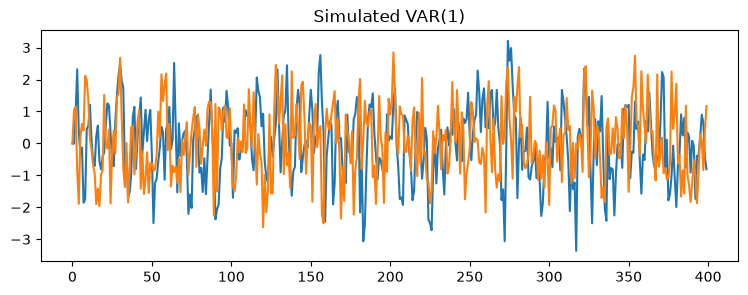

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
A = np.array([[0.5, 0.2],[-0.1, 0.4]])
print("eigenvalues of A:", np.linalg.eigvals(A), " moduli:", np.abs(np.linalg.eigvals(A)))
yprev = np.array([10.0, 5.0]); eps = np.array([0.3,-0.2])
print("conditional mean:", A@yprev, " realised:", A@yprev+eps)
rng = np.random.default_rng(12)
n = 400
Y = np.zeros((n,2))
for t in range(1,n):
    Y[t] = A@Y[t-1] + rng.normal(scale=1.0, size=2)
plt.figure(figsize=(9,3)); plt.plot(Y); plt.title("Simulated VAR(1)"); plt.show()

The eigenvalues are complex, $0.45\pm0.13i$, each with modulus $\approx0.47<1$, so the VAR is stable. The hand calculation $\hat y_t=(6,1)^\top$ matches the note.

In [2]:
from statsmodels.tsa.api import VAR
model = VAR(Y)
sel = model.select_order(maxlags=6)
print(sel.summary())
res = model.fit(1)
print("estimated A:\n", res.coefs[0].round(3))
print("stable:", res.is_stable())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      0.4459      0.4661       1.562      0.4539
1    -0.04900    0.01155*      0.9522   -0.02501*
2    -0.04972     0.05121      0.9515   -0.009726
3   -0.05663*     0.08466     0.9450*  -0.0006415
4    -0.04636      0.1353      0.9547     0.02562
5    -0.04358      0.1784      0.9574     0.04440
6    -0.02706      0.2353      0.9733     0.07691
-------------------------------------------------
estimated A:
 [[ 0.498  0.289]
 [-0.099  0.315]]
stable: True


BIC and HQIC pick lag 1 (the true order) while AIC, which penalises parameters less, drifts to a larger lag: criteria can disagree, so they only narrow the candidate set. The estimated coefficient matrix is close to the true $A_1$, and the root check confirms stability.

x -> z (true A[1,0]=-0.1):  p = 0.0318
z -> x (true A[0,1]= 0.2):  p = 0.0


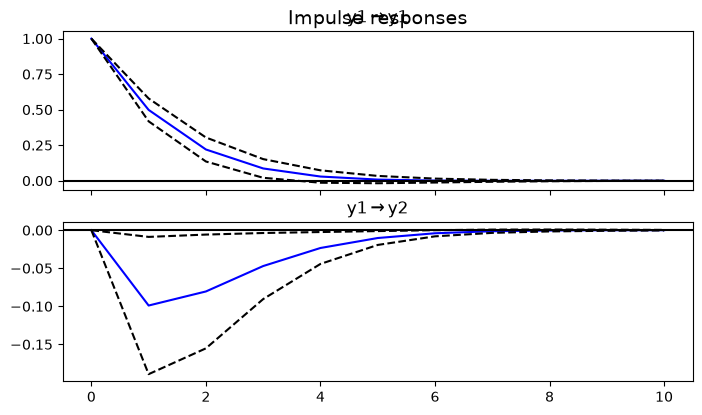

In [3]:
g = res.test_causality(caused=1, causing=0, kind="f")
print("x -> z (true A[1,0]=-0.1):  p =", round(g.pvalue,4))
g2 = res.test_causality(caused=0, causing=1, kind="f")
print("z -> x (true A[0,1]= 0.2):  p =", round(g2.pvalue,4))
irf = res.irf(10)
fig = irf.plot(orth=False, impulse=0, figsize=(7,4)); plt.show()

The F-tests ask whether lagged values of one variable add incremental predictive information; this is predictability, not causality. The impulse responses are columns of $\Psi_h=A_1^h$ (non-orthogonalised). Orthogonalised responses would depend on the variable ordering.

In [4]:
# Cointegration: two I(1) series sharing a stochastic trend, y = 1.4 x + u
rng = np.random.default_rng(3)
n = 500
x = np.cumsum(rng.normal(size=n))
u = np.zeros(n)
for t in range(1,n): u[t] = 0.7*u[t-1] + rng.normal(scale=0.5)
yy = 1.4*x + u
from statsmodels.tsa.stattools import adfuller, coint
print("ADF p-value  x:", round(adfuller(x)[1],3), " y:", round(adfuller(yy)[1],3))
print("ADF p-value spread y-1.4x:", round(adfuller(yy-1.4*x)[1],4))
print("Engle-Granger coint p-value:", round(coint(yy, x)[1],4))
# spurious regression: two independent random walks
cl, cd = [], []
for _ in range(500):
    w1, w2 = np.cumsum(rng.normal(size=200)), np.cumsum(rng.normal(size=200))
    cl.append(np.corrcoef(w1,w2)[0,1]); cd.append(np.corrcoef(np.diff(w1),np.diff(w2))[0,1])
print("independent random walks, 500 pairs: share with |corr|>0.5 in levels =", np.mean(np.abs(cl)>0.5).round(2),
      " in differences =", np.mean(np.abs(cd)>0.5).round(2))

ADF p-value  x: 0.918  y: 0.904
ADF p-value spread y-1.4x: 0.0
Engle-Granger coint p-value: 0.0


independent random walks, 500 pairs: share with |corr|>0.5 in levels = 0.36  in differences = 0.0


Both levels have unit roots, but the spread $y_t-1.4x_t$ is stationary, so the pair is cointegrated. Two independent random walks, by contrast, often show a large level correlation (a sizeable share of the 500 pairs exceeds 0.5) that disappears in differences: the spurious-regression problem.

In [5]:
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen
data = np.column_stack([yy, x])
print("Johansen trace stats:", coint_johansen(data, det_order=0, k_ar_diff=1).lr1.round(1), " 5% crit:", coint_johansen(data, det_order=0, k_ar_diff=1).cvt[:,1])
vecm = VECM(data, k_ar_diff=1, coint_rank=1, deterministic="n").fit()
print("beta (normalised):", (vecm.beta[:,0]/vecm.beta[0,0]).round(3))
print("alpha (adjustment):", vecm.alpha[:,0].round(3))

Johansen trace stats: [75.   0.1]  5% crit: [15.4943  3.8415]
beta (normalised): [ 1.    -1.403]
alpha (adjustment): [-0.258  0.041]


The Johansen trace statistic for rank 0 exceeds its critical value (one cointegrating relation), and the normalised $\beta\approx(1,-1.4)$ recovers the long-run relation. The loading $\alpha_y<0$ means $y$ adjusts back toward equilibrium after a positive deviation, while $x$ barely adjusts.